In [1]:
import pandas as pd
import numpy as np

START, END = "2015-01-01", "2026-01-01"    # END is exclusive

dax = pd.read_csv("../data/dax_daily.csv", index_col=0, parse_dates=True)
dax = dax.loc[START:END]
dax = dax[dax.index < END]

In [2]:
returns = np.log(dax["Close"]).diff().dropna()
returns.name = "log_return"
print(returns.shape)       # expect (2789,)
returns.head()

(2789,)


Date
2015-01-05   -0.030314
2015-01-06   -0.000370
2015-01-07    0.005111
2015-01-08    0.033009
2015-01-09   -0.019410
Name: log_return, dtype: float64

In [3]:
simple = dax["Close"].pct_change().dropna()
simple.name = "simple_return"

compare = pd.concat([simple, returns], axis=1)
compare["gap_pct_pts"] = (compare["log_return"] - compare["simple_return"]) * 100

print(compare.describe().round(5))
print()
print(compare.loc[["2015-01-05", "2020-03-12", "2020-03-24", "2020-04-06"]].round(5))

       simple_return  log_return  gap_pct_pts
count     2789.00000  2789.00000   2789.00000
mean         0.00040     0.00033     -0.00724
std          0.01201     0.01204      0.02500
min         -0.12239    -0.13055     -0.81624
25%         -0.00494    -0.00496     -0.00628
50%          0.00079     0.00079     -0.00167
75%          0.00660     0.00658     -0.00036
max          0.10976     0.10414     -0.00000

            simple_return  log_return  gap_pct_pts
Date                                              
2015-01-05       -0.02986    -0.03031     -0.04549
2020-03-12       -0.12239    -0.13055     -0.81624
2020-03-24        0.10976     0.10414     -0.56161
2020-04-06        0.05768     0.05607     -0.16019


               count    mean     min
simple_return                       
under 1%        1976 -0.0012 -0.0050
1-2%             600 -0.0102 -0.0200
2-5%             204 -0.0428 -0.1269
over 5%            9 -0.3195 -0.8162


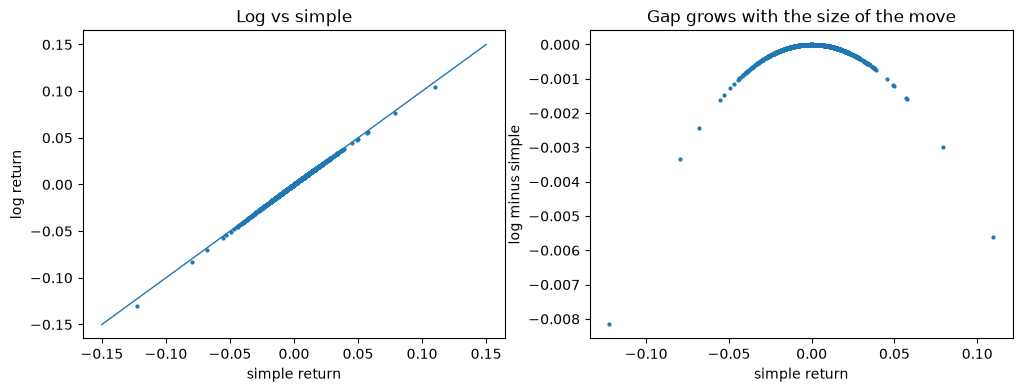

In [4]:
import matplotlib.pyplot as plt

size = pd.cut(simple.abs(), [0, 0.01, 0.02, 0.05, 1],
              labels=["under 1%", "1-2%", "2-5%", "over 5%"])
print(compare.groupby(size, observed=True)["gap_pct_pts"].agg(["count", "mean", "min"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(simple, returns, s=4)
axes[0].plot([-0.15, 0.15], [-0.15, 0.15], lw=1)       # the line log = simple
axes[0].set_xlabel("simple return"); axes[0].set_ylabel("log return")
axes[0].set_title("Log vs simple")

axes[1].scatter(simple, returns - simple, s=4)
axes[1].set_xlabel("simple return"); axes[1].set_ylabel("log minus simple")
axes[1].set_title("Gap grows with the size of the move")

fig.savefig("../results/figures/02_simple_vs_log.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
first, last = dax["Close"].iloc[0], dax["Close"].iloc[-1]

print("True total return from prices:     ", round(last / first - 1, 4))
print("Compounding the simple returns:    ", round((1 + simple).prod() - 1, 4))
print("Summing the simple returns:        ", round(simple.sum(), 4))
print()
print("Summing the log returns:           ", round(returns.sum(), 4))
print("exp(sum of log returns) - 1:       ", round(np.exp(returns.sum()) - 1, 4))

True total return from prices:      1.508
Compounding the simple returns:     1.508
Summing the simple returns:         1.1215

Summing the log returns:            0.9195
exp(sum of log returns) - 1:        1.508


In [6]:
p0, p1, p2 = 100, 50, 100        # price halves, then doubles back

print("simple:", p1 / p0 - 1, p2 / p1 - 1)             # -0.5 and +1.0
print("log:   ", np.log(p1 / p0), np.log(p2 / p1))     # -0.693 and +0.693

print("Worst simple return in the data:", round(simple.min(), 4))
print("Worst log return in the data:   ", round(returns.min(), 4))

simple: -0.5 1.0
log:    -0.6931471805599453 0.6931471805599453
Worst simple return in the data: -0.1224
Worst log return in the data:    -0.1305


In [7]:
from scipy import stats

print("Count:           ", returns.count())
print("Mean (daily):    ", round(returns.mean(), 6))
print("Std (daily):     ", round(returns.std(), 6))
print("Min / Max:       ", round(returns.min(), 4), "/", round(returns.max(), 4))
print("Skewness:        ", round(returns.skew(), 3))
print("Excess kurtosis: ", round(returns.kurt(), 3))
print("Annualised vol:  ", round(returns.std() * np.sqrt(252), 4))

jb_stat, jb_p = stats.jarque_bera(returns)
print("Jarque-Bera p-value:", jb_p)

Count:            2789
Mean (daily):     0.00033
Std (daily):      0.012043
Min / Max:        -0.1305 / 0.1041
Skewness:         -0.604
Excess kurtosis:  10.283
Annualised vol:   0.1912
Jarque-Bera p-value: 0.0


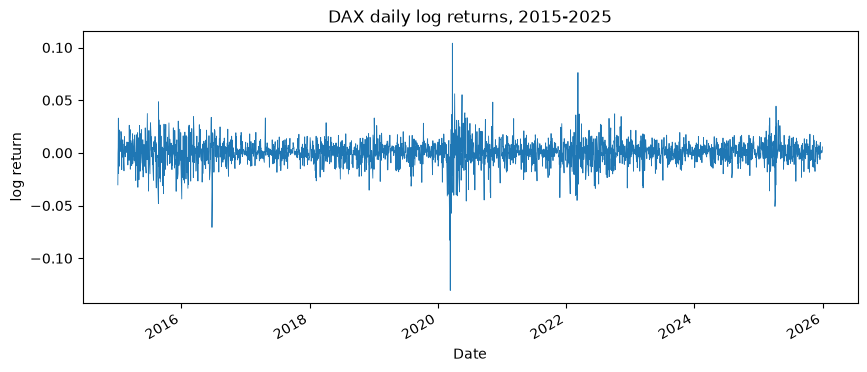

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
returns.plot(ax=ax, lw=0.6)
ax.set_title("DAX daily log returns, 2015-2025")
ax.set_ylabel("log return")
fig.savefig("../results/figures/02_log_returns.png", dpi=150, bbox_inches="tight")
plt.show()

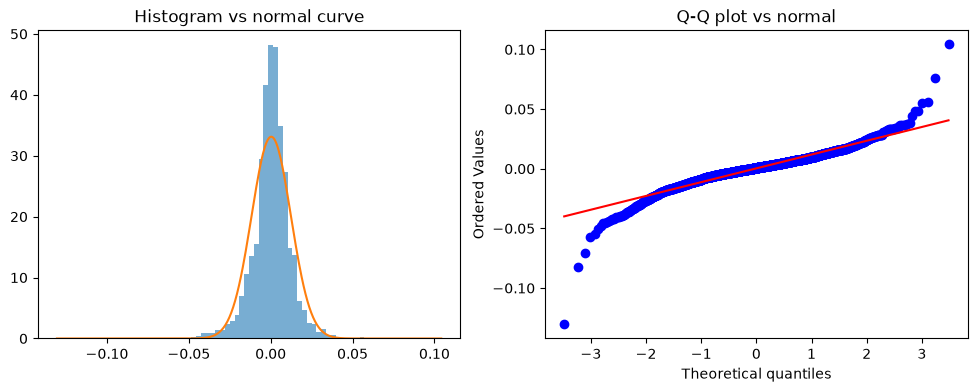

In [9]:
mu, sigma = returns.mean(), returns.std()
x = np.linspace(returns.min(), returns.max(), 400)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(returns, bins=80, density=True, alpha=0.6)
axes[0].plot(x, stats.norm.pdf(x, mu, sigma))
axes[0].set_title("Histogram vs normal curve")

stats.probplot(returns, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot vs normal")

fig.savefig("../results/figures/02_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

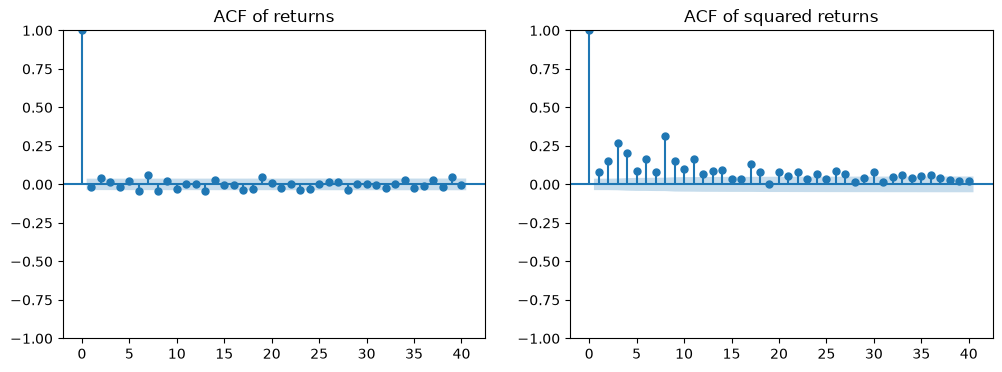

      lb_stat  lb_pvalue
10  32.594601   0.000319
       lb_stat      lb_pvalue
10  887.014691  3.967573e-184


In [10]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(returns,      lags=40, ax=axes[0], title="ACF of returns")
plot_acf(returns**2,   lags=40, ax=axes[1], title="ACF of squared returns")
fig.savefig("../results/figures/02_acf.png", dpi=150, bbox_inches="tight")
plt.show()

print(acorr_ljungbox(returns,    lags=[10]))
print(acorr_ljungbox(returns**2, lags=[10]))

In [11]:
returns.to_csv("../data/dax_log_returns.csv")